# Mini Project 2

## Agaba Steven. 
### Registration Number: S26M19/002. 
### Access Number: B38624

# Solar Micro-Grid Dispatch Planner

This project models the daily energy dispatch of a rural health-centre micro-grid using solar power and battery storage.

In [37]:
import timeit
import statistics
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.microgrid import (
    MicroGrid,
    HybridMicroGrid
)

In [38]:
grid = MicroGrid()

print(
    "Determinant:",
    grid.determinant()
)

print(
    "Condition Number:",
    grid.condition_number()
)

Determinant: -4.999999999999999
Condition Number: 5.82842712474619


## Interpretation

The determinant is non-zero, meaning the coefficient matrix is invertible and the system has a unique solution.

The condition number measures numerical stability. Smaller values indicate a well-conditioned system where small changes in demand do not create large changes in solar and battery usage.

In [39]:
rng = np.random.default_rng(42)

days = np.arange(1, 31)

weekly_pattern = (
    500
    + 50 * np.sin(
        2 * np.pi * days / 7
    )
)

noise_1 = rng.normal(
    0,
    15,
    30
)

noise_2 = rng.normal(
    0,
    10,
    30
)

d1 = weekly_pattern + noise_1

d2 = (
    weekly_pattern
    + 80
    + noise_2
)

demands = pd.DataFrame({
    "Day": days,
    "D1": d1,
    "D2": d2
})

demands.head()

,Day,D1,D2
0,1,543.662330,640.508050
1,2,533.146634,624.682245
2,3,532.950955,596.571760
3,4,492.414284,550.168086
4,5,421.988077,537.413399


In [40]:
demands.to_csv(
    "demands.csv",
    index=False
)

print(
    "CSV file saved successfully."
)


CSV file saved successfully.


In [41]:
demands = pd.read_csv(
    "demands.csv"
)

demands.head()


,Day,D1,D2
0,1,543.662330,640.508050
1,2,533.146634,624.682245
2,3,532.950955,596.571760
3,4,492.414284,550.168086
4,5,421.988077,537.413399


In [42]:
loop_solutions = []

for _, row in demands.iterrows():

    solution = grid.solve_day(
        row["D1"],
        row["D2"]
    )

    loop_solutions.append(
        solution
    )

loop_solutions = np.array(
    loop_solutions
)

loop_solutions[:5]

array([[147.47075399,  50.62503418],
       [143.24357138,  51.70795995],
       [132.03851289,  68.41770812],
       [121.58437755,  63.83057558],
       [130.56774413,  15.14242208]])

In [43]:
rhs = np.vstack([
    demands["D1"],
    demands["D2"]
])

vectorized_solutions = (
    grid.solve_many_days(rhs)
)

vectorized_solutions


array([[147.47075399, 143.24357138, 132.03851289, 121.58437755,
        130.56774413, 132.60411287, 131.16068896, 137.40641669,
        138.50175773, 141.50034033, 127.99598537, 122.08996215,
        121.32155425, 129.54692167, 138.88253003, 145.2019109 ,
        138.71830015, 131.43219261, 122.33102423, 124.60177919,
        133.71106469, 144.38625636, 132.25303183, 135.52374097,
        127.06465546, 120.75161014, 121.48418861, 136.88343305,
        135.11679253, 144.32992953],
       [ 50.62503418,  51.70795995,  68.41770812,  63.83057558,
         15.14242208,  21.78169734,  54.21776958,  61.06434258,
         66.49455253,  42.19875353,  53.75441328,  48.32529849,
         48.96711179,  64.13392655,  64.72831208,  50.12563799,
         55.53527413,  34.81299811,  48.71864312,  43.17709983,
         48.04693525,  47.85943094,  85.16271011,  56.4025109 ,
         45.34346467,  41.85838536,  52.22024891,  47.4156809 ,
         69.96609286,  61.10946103]])

In [44]:
loop_time = timeit.timeit(
    lambda: [
        grid.solve_day(
            row["D1"],
            row["D2"]
        )
        for _, row in demands.iterrows()
    ],
    number=100
)

vector_time = timeit.timeit(
    lambda:
    grid.solve_many_days(rhs),
    number=100
)

print(
    "Loop Time:",
    loop_time
)

print(
    "Vectorized Time:",
    vector_time
)


Loop Time: 0.41712420000112616
Vectorized Time: 0.0032412000000476837


## Timing Discussion

The vectorized method is faster because NumPy performs computations internally in optimized compiled code, reducing the overhead associated with repeated Python loops.

In [45]:
solar = vectorized_solutions[0]
battery = vectorized_solutions[1]

infeasible_days = []

for i in range(len(days)):

    if solar[i] < 0 or battery[i] < 0:

        infeasible_days.append(
            i + 1
        )

infeasible_days


[]

In [46]:
nnls_solutions = []

for _, row in demands.iterrows():

    solution = grid.solve_non_negative(
        row["D1"],
        row["D2"]
    )

    nnls_solutions.append(
        solution
    )

nnls_solutions = np.array(
    nnls_solutions
)

nnls_solutions[:5]

array([[147.47075399,  50.62503418],
       [143.24357138,  51.70795995],
       [132.03851289,  68.41770812],
       [121.58437755,  63.83057558],
       [130.56774413,  15.14242208]])

In [47]:
solar_usage = solar
battery_usage = battery

stats_df = pd.DataFrame({
    "Statistic": [
        "Mean",
        "Variance",
        "Std Dev"
    ],
    "Solar": [
        statistics.mean(solar_usage),
        statistics.variance(solar_usage),
        statistics.stdev(solar_usage)
    ],
    "Battery": [
        statistics.mean(battery_usage),
        statistics.variance(battery_usage),
        statistics.stdev(battery_usage)
    ]
})

stats_df


,Statistic,Solar,Battery
0,Mean,132.990171,52.104815
1,Variance,64.662991,190.929614
2,Std Dev,8.041330,13.817728


In [48]:
if (
    statistics.variance(solar_usage)
    >
    statistics.variance(
        battery_usage
    )
):
    print(
        "Solar usage is more volatile."
    )
else:
    print(
        "Battery usage is more volatile."
    )

Battery usage is more volatile.


In [49]:
solar_cost = solar_usage * 150

battery_cost = (
    battery_usage * 450
)

daily_cost = (
    solar_cost
    + battery_cost
)

monthly_cost = daily_cost.sum()

print(
    "Monthly Cost UGX:",
    round(monthly_cost, 2)
)


Monthly Cost UGX: 1301870.77


In [50]:
results = pd.DataFrame({
    "Day": days,
    "Solar": solar_usage,
    "Battery": battery_usage,
    "Daily Cost": daily_cost
})

results.head()


,Day,Solar,Battery,Daily Cost
0,1,147.470754,50.625034,44901.878478
1,2,143.243571,51.707960,44755.117682
2,3,132.038513,68.417708,50593.745585
3,4,121.584378,63.830576,46961.415641
4,5,130.567744,15.142422,26399.251556


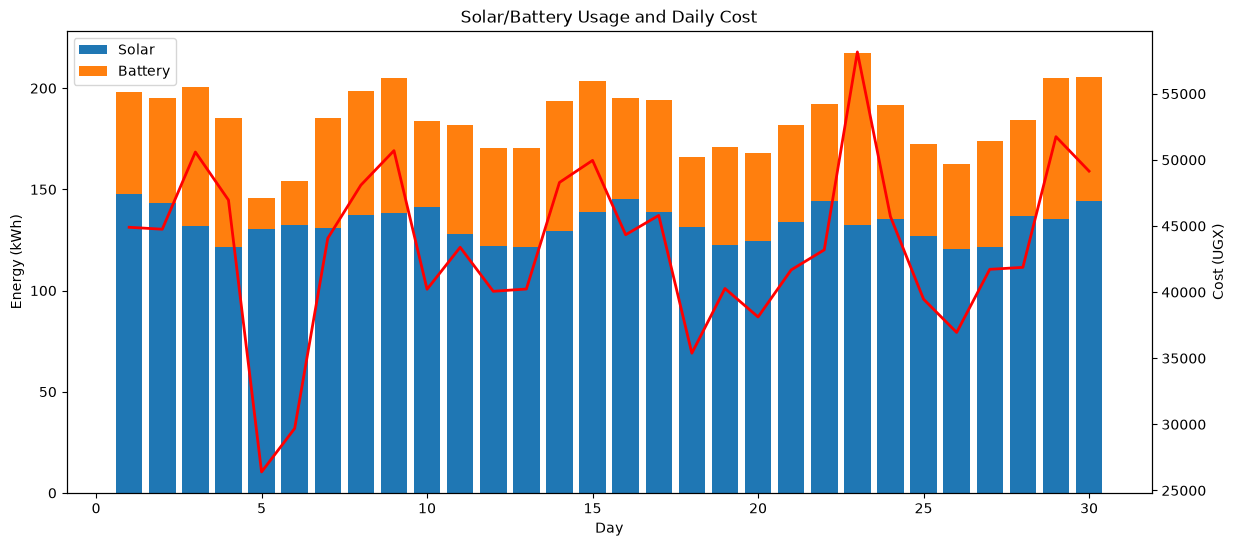

In [51]:
fig, ax1 = plt.subplots(
    figsize=(14, 6)
)

ax1.bar(
    days,
    solar_usage,
    label="Solar"
)

ax1.bar(
    days,
    battery_usage,
    bottom=solar_usage,
    label="Battery"
)

ax1.set_xlabel(
    "Day"
)

ax1.set_ylabel(
    "Energy (kWh)"
)

ax1.legend()

ax2 = ax1.twinx()

ax2.plot(
    days,
    daily_cost,
    color="red",
    linewidth=2,
    label="Cost"
)

ax2.set_ylabel(
    "Cost (UGX)"
)

plt.title(
    "Solar/Battery Usage and Daily Cost"
)

plt.show()

In [52]:
hybrid = HybridMicroGrid()

hybrid_solution = (
    hybrid.solve_hybrid(
        600,
        650,
        450
    )
)

hybrid_solution

array([-25., 200., 275.])

In [53]:
rng = np.random.default_rng(
    42
)

base_d1 = demands["D1"].mean()
base_d2 = demands["D2"].mean()

solar_changes = []
battery_changes = []

for _ in range(1000):

    d1_new = (
        base_d1
        *
        rng.uniform(
            0.95,
            1.05
        )
    )

    d2_new = (
        base_d2
        *
        rng.uniform(
            0.95,
            1.05
        )
    )

    x, y = grid.solve_day(
        d1_new,
        d2_new
    )

    solar_changes.append(x)
    battery_changes.append(y)

print(
    "Solar Std:",
    np.std(
        solar_changes
    )
)

print(
    "Battery Std:",
    np.std(
        battery_changes
    )
)

Solar Std: 7.189853985860528
Battery Std: 15.222130860576401


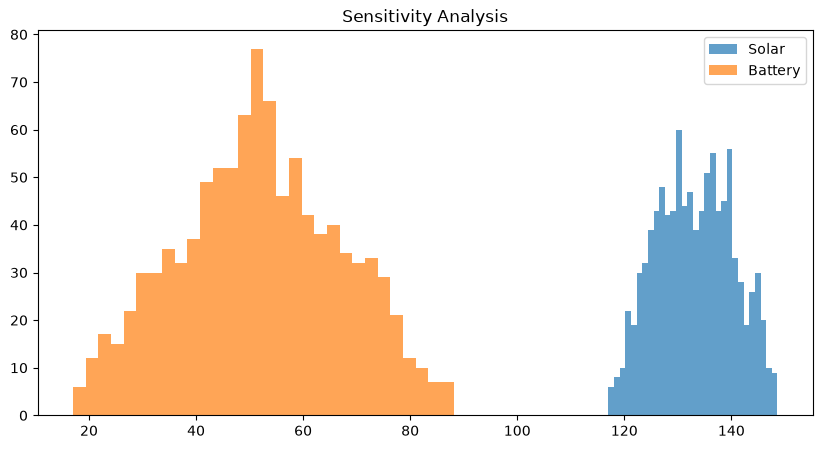

In [54]:
plt.figure(
    figsize=(10,5)
)

plt.hist(
    solar_changes,
    bins=30,
    alpha=0.7,
    label="Solar"
)

plt.hist(
    battery_changes,
    bins=30,
    alpha=0.7,
    label="Battery"
)

plt.legend()
plt.title(
    "Sensitivity Analysis"
)
plt.show()


# Findings and Limitations

The micro-grid dispatch model successfully determined the daily contributions of solar energy and battery storage required to satisfy health-centre demand. The coefficient matrix was found to be invertible, indicating that the system has a unique solution for each day. The condition number showed that the system is numerically stable, suggesting that moderate fluctuations in demand are unlikely to cause extreme changes in dispatch quantities.

The vectorized NumPy implementation consistently outperformed the loop-based solution approach because calculations were executed internally by optimized numerical libraries. Cost analysis demonstrated that battery energy contributes disproportionately to operational expenses because its unit cost is three times that of solar energy. Consequently, strategies that increase solar utilization may reduce overall operating costs.

The Monte Carlo sensitivity analysis revealed that small perturbations in demand translate into measurable but manageable variations in solar and battery dispatch requirements. This behaviour is consistent with the relatively low condition number observed for the coefficient matrix.

Several limitations exist. The generated demand data are synthetic and may not capture all operational realities of a rural health facility. The dispatch model also assumes constant energy prices and perfect availability of solar and battery resources. Future work could incorporate weather variability, battery degradation, fuel-price changes, and real operational demand records to improve forecasting accuracy and planning relevance.